In [1]:
# ============================================================
# CELL 1 ▸ Install + Imports
# ============================================================
import subprocess, sys

for pkg in ['librosa','soundfile','audioread','numpy','pandas',
            'matplotlib','seaborn','scikit-learn','tqdm','scipy']:
    try:   __import__('sklearn' if pkg=='scikit-learn' else pkg)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg],
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import os, re, glob, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import librosa
import librosa.display
from scipy import stats as scipy_stats
from sklearn.model_selection import StratifiedKFold
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,'font.size':11,
                     'axes.titlesize':13,'savefig.bbox':'tight',
                     'savefig.pad_inches':0.1})
print(f'librosa {librosa.__version__}  |  numpy {np.__version__}')
print('Imports complete.')

librosa 0.11.0  |  numpy 2.4.6
Imports complete.


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Change AUDIO_ROOT to match your Kaggle dataset path.

AUDIO_ROOT = ('/kaggle/input/datasets/mlfarhan/audio-classification/audio genre classification')

WORK_DIR = '/kaggle/working'
OUT_DIR  = os.path.join(WORK_DIR, 'part1_outputs')
FIG_DIR  = os.path.join(OUT_DIR,  'figures')
for d in [OUT_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

AUDIO_EXT = ('.mp3', '.wav', '.flac', '.ogg', '.m4a', '.aac')
SR         = 22050
SEG_DUR    = 10
N_FOLDS    = 5
SEED       = 42

CLASS_NAMES = [
    'Bangla_Band_Collection', 'Bangla_ancholik',
    'Bangla_baby_rhymes',     'Bangla_rabindra_sangeet',
    'Bangla_romantic',        'Classic_Songs_',
    'Islamic_Melody',         'Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection'  : 'Band',
    'Bangla_ancholik'         : 'Ancholik',
    'Bangla_baby_rhymes'      : 'Rhymes',
    'Bangla_rabindra_sangeet' : 'Rabindra',
    'Bangla_romantic'         : 'Romantic',
    'Classic_Songs_'          : 'Classic',
    'Islamic_Melody'          : 'Islamic',
    'Nazrul_Geeti_'           : 'Nazrul',
}
COARSE_MAP = {
    'Bangla_Band_Collection'  : 'Contemporary_Pop',
    'Bangla_ancholik'         : 'Folk_Regional',
    'Bangla_baby_rhymes'      : 'Folk_Regional',
    'Bangla_rabindra_sangeet' : 'Classical_Tagore',
    'Bangla_romantic'         : 'Contemporary_Pop',
    'Classic_Songs_'          : 'Classical_Tagore',
    'Islamic_Melody'          : 'Devotional_Spiritual',
    'Nazrul_Geeti_'           : 'Devotional_Spiritual',
}
COARSE_NAMES = sorted(set(COARSE_MAP.values()))
N_CLASSES    = len(CLASS_NAMES)
SHORT_NAMES  = [CLASS_SHORT[c] for c in CLASS_NAMES]

CLASS_PAL   = dict(zip(CLASS_NAMES, sns.color_palette('tab10', N_CLASSES)))
COARSE_PAL  = dict(zip(COARSE_NAMES, sns.color_palette('Set2',  4)))

print('Configuration loaded.')
print(f'  Audio root : {AUDIO_ROOT}')
print(f'  N_CLASSES  : {N_CLASSES}')
print(f'  N_FOLDS    : {N_FOLDS}')

Configuration loaded.
  Audio root : /kaggle/input/datasets/mlfarhan/audio-classification/audio genre classification
  N_CLASSES  : 8
  N_FOLDS    : 5


In [3]:
# ============================================================
# CELL 3 ▸ Dataset Discovery
# ============================================================
# Scans the dataset root for audio files per class.

def find_root(base, class_names):
    for root, dirs, _ in os.walk(base):
        if sum(1 for d in dirs
               if any(c.strip('_ ').lower() in d.strip('_ ').lower()
                      for c in class_names)) >= 4:
            return root
    return base

DATASET_ROOT = find_root(AUDIO_ROOT, CLASS_NAMES)
print(f'Dataset root: {DATASET_ROOT}')

class_files = {}
for cls in CLASS_NAMES:
    folder = os.path.join(DATASET_ROOT, cls)
    if not os.path.isdir(folder):          # fuzzy match
        for d in os.listdir(DATASET_ROOT):
            if cls.strip('_ ').lower() in d.strip('_ ').lower():
                folder = os.path.join(DATASET_ROOT, d); break
    files = []
    if os.path.isdir(folder):
        for ext in AUDIO_EXT:
            files += glob.glob(os.path.join(folder, f'*{ext}'))
            files += glob.glob(os.path.join(folder, f'*{ext.upper()}'))
    class_files[cls] = sorted(set(files))

total = sum(len(v) for v in class_files.values())
print(f'\n  {"Class":<35} {"Files":>6}')
print(f'  {"-"*35} {"------":>6}')
for cls in CLASS_NAMES:
    flag = '' if class_files[cls] else '  ← NOT FOUND'
    print(f'  {cls:<35} {len(class_files[cls]):>6}{flag}')
print(f'  {"─"*35} {"──────":>6}')
print(f'  {"TOTAL":<35} {total:>6}')

missing = [c for c in CLASS_NAMES if not class_files[c]]
if missing:
    print(f'\n⚠️  Missing classes: {missing}')
    print('   Check AUDIO_ROOT and class folder names.')
else:
    print('\n✅ All 8 classes found.')

Dataset root: /kaggle/input/datasets/mlfarhan/audio-classification/audio genre classification

  Class                                Files
  ----------------------------------- ------
  Bangla_Band_Collection                 287
  Bangla_ancholik                        169
  Bangla_baby_rhymes                     153
  Bangla_rabindra_sangeet                152
  Bangla_romantic                        291
  Classic_Songs_                         245
  Islamic_Melody                         319
  Nazrul_Geeti_                          254
  ─────────────────────────────────── ──────
  TOTAL                                 1870

✅ All 8 classes found.


In [4]:
# ============================================================
# CELL 4 ▸ Audio Quality Checks
# ============================================================
# Reads audio duration and checks for silent/corrupt files.
# Uses librosa.get_duration (reads header only — fast).

MIN_DUR = SEG_DUR           # at least one segment
RMS_THR = 1e-4              # silence threshold

print('Checking audio quality (reading headers)...\n')

file_records = []
seen_stems   = {}           # deduplicate by file stem

for cls in CLASS_NAMES:
    n_ok, n_short, n_dup = 0, 0, 0
    for fpath in tqdm(class_files[cls], desc=f'  {cls[:28]}', leave=False):
        stem = os.path.splitext(os.path.basename(fpath))[0].lower().strip()
        if stem in seen_stems:
            n_dup += 1; continue
        seen_stems[stem] = fpath

        try:
            dur = librosa.get_duration(path=fpath)
        except Exception:
            dur = 0.0

        if dur < MIN_DUR:
            n_short += 1; continue

        n_ok += 1
        n_segs_est = int(dur // SEG_DUR)
        file_records.append({
            'filepath'     : fpath,
            'label'        : cls,
            'coarse'       : COARSE_MAP[cls],
            'song_id'      : os.path.splitext(os.path.basename(fpath))[0],
            'duration_s'   : round(dur, 2),
            'n_segs_est'   : n_segs_est,
        })

    print(f'  {cls:<35} ok={n_ok:>4}  short={n_short:>3}  dup={n_dup:>3}')

file_df = pd.DataFrame(file_records)
print(f'\nTotal clean files : {len(file_df):,}')
print(f'Est. total segments: {file_df["n_segs_est"].sum():,}')
print(f'Est. total audio   : {file_df["duration_s"].sum()/3600:.1f} hours')

Checking audio quality (reading headers)...



  Bangla_Band_Collection:   0%|          | 0/287 [00:00<?, ?it/s]

  Bangla_Band_Collection              ok= 287  short=  0  dup=  0


  Bangla_ancholik:   0%|          | 0/169 [00:00<?, ?it/s]

  Bangla_ancholik                     ok= 169  short=  0  dup=  0


...

  Classic_Songs_                      ok= 245  short=  0  dup=  0


  Islamic_Melody:   0%|          | 0/319 [00:00<?, ?it/s]

  Islamic_Melody                      ok= 319  short=  0  dup=  0


  Nazrul_Geeti_:   0%|          | 0/254 [00:00<?, ?it/s]

  Nazrul_Geeti_                       ok= 254  short=  0  dup=  0

Total clean files : 1,870
Est. total segments: 60,579
Est. total audio   : 170.8 hours


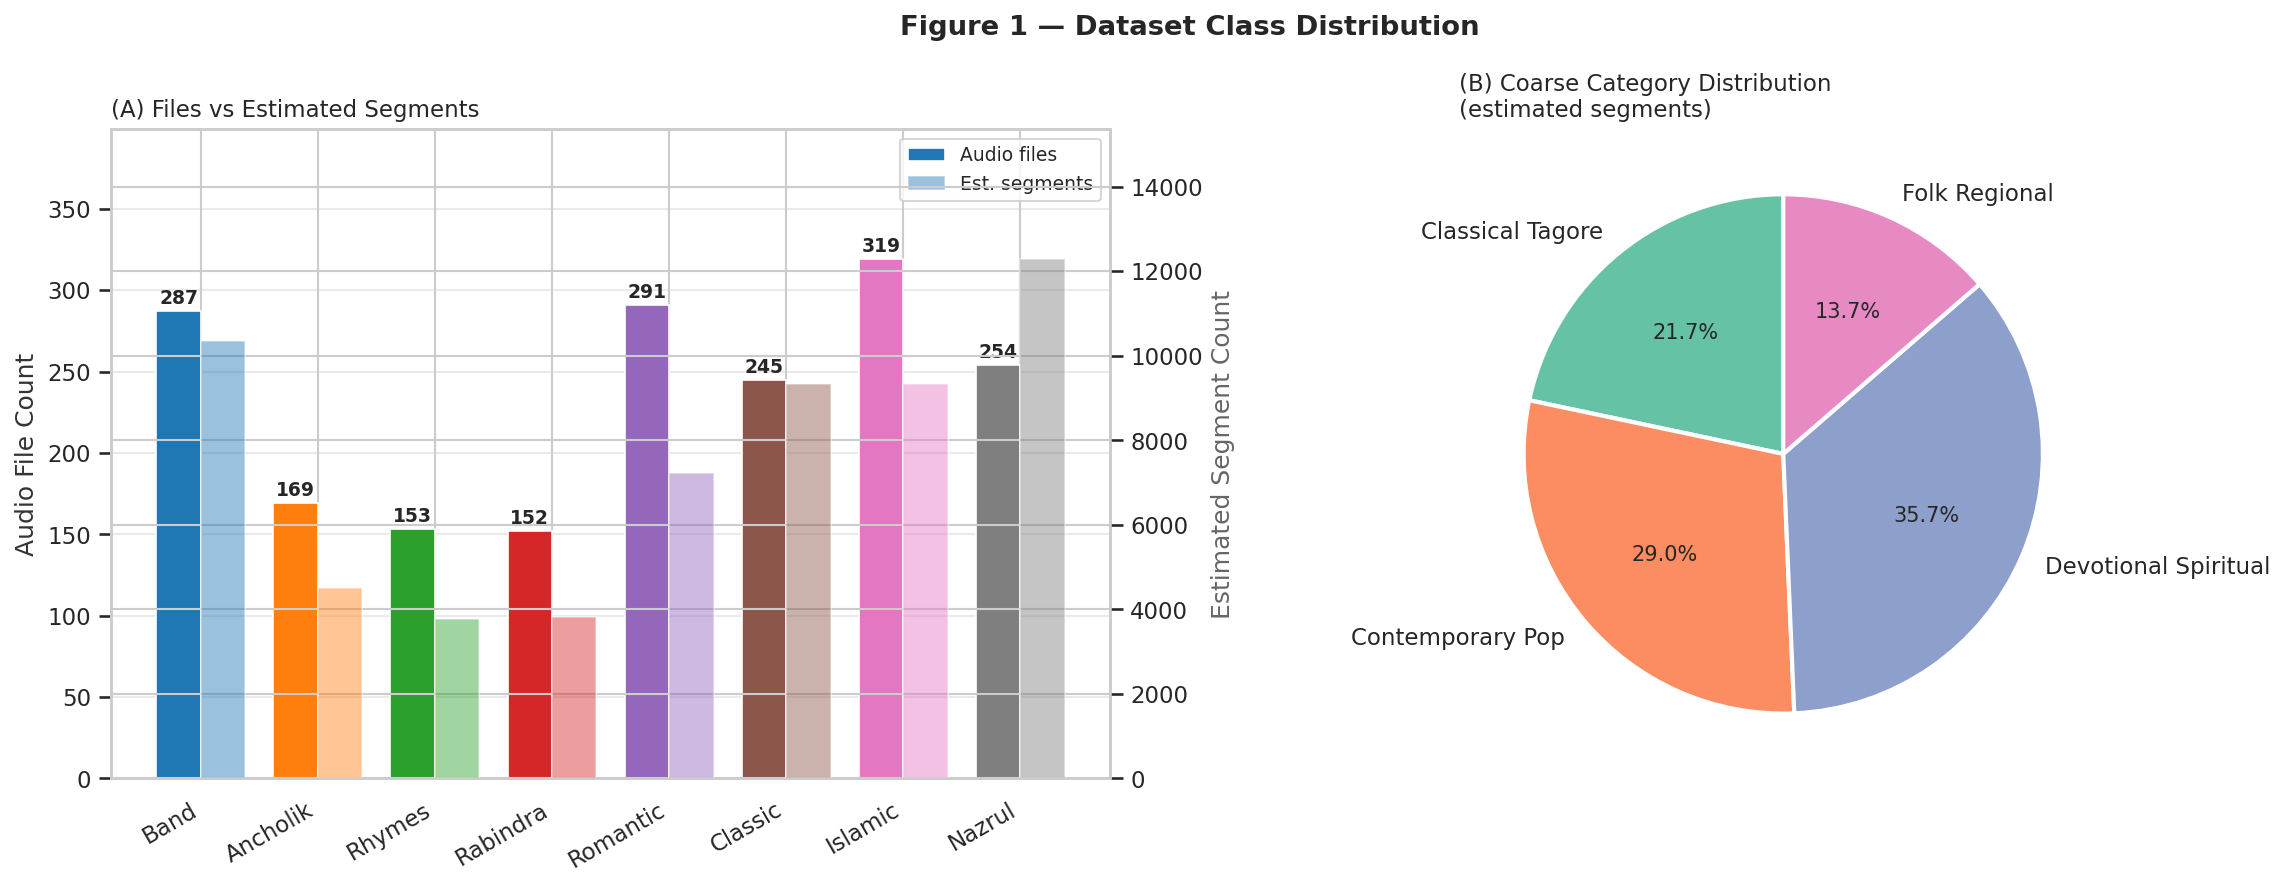

Saved: /kaggle/working/part1_outputs/figures/fig01_class_distribution.png


In [5]:
# ============================================================
# CELL 5 ▸ Figure 1 — Class Distribution
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Figure 1 — Dataset Class Distribution', fontweight='bold')

# Panel A: file + segment counts
ax = axes[0]
cls_stats = (file_df.groupby('label')
             .agg(files=('filepath','count'),
                  segs=('n_segs_est','sum'))
             .reindex(CLASS_NAMES))

x    = np.arange(N_CLASSES)
w    = 0.38
clrs = [CLASS_PAL[c] for c in CLASS_NAMES]

b1 = ax.bar(x - w/2, cls_stats['files'], w,
            color=clrs, edgecolor='white', linewidth=0.8,
            label='Audio files', zorder=3)
ax2 = ax.twinx()
ax2.bar(x + w/2, cls_stats['segs'], w,
        color=clrs, edgecolor='white', linewidth=0.8,
        alpha=0.45, label='Est. segments', zorder=3)

for bar in b1:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+2, str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(SHORT_NAMES, rotation=30, ha='right')
ax.set_ylabel('Audio File Count', color='#333')
ax2.set_ylabel('Estimated Segment Count', color='#666')
ax.set_title('(A) Files vs Estimated Segments', loc='left', fontsize=11)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)
ax.set_ylim(0, cls_stats['files'].max()*1.25)
ax2.set_ylim(0, cls_stats['segs'].max()*1.25)

lines1,labs1 = ax.get_legend_handles_labels()
lines2,labs2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, labs1+labs2, loc='upper right', fontsize=9)

# Panel B: coarse-level pie
ax = axes[1]
coarse_segs = (file_df.groupby('coarse')['n_segs_est'].sum()
               .reindex(COARSE_NAMES))
clrs_c = [COARSE_PAL[c] for c in COARSE_NAMES]
wedges, _, autotexts = ax.pie(
    coarse_segs, labels=[c.replace('_',' ') for c in COARSE_NAMES],
    colors=clrs_c, autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2))
for at in autotexts: at.set_fontsize(10)
ax.set_title('(B) Coarse Category Distribution\n(estimated segments)',
             loc='left', fontsize=11)

plt.tight_layout()
path = os.path.join(FIG_DIR, 'fig01_class_distribution.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

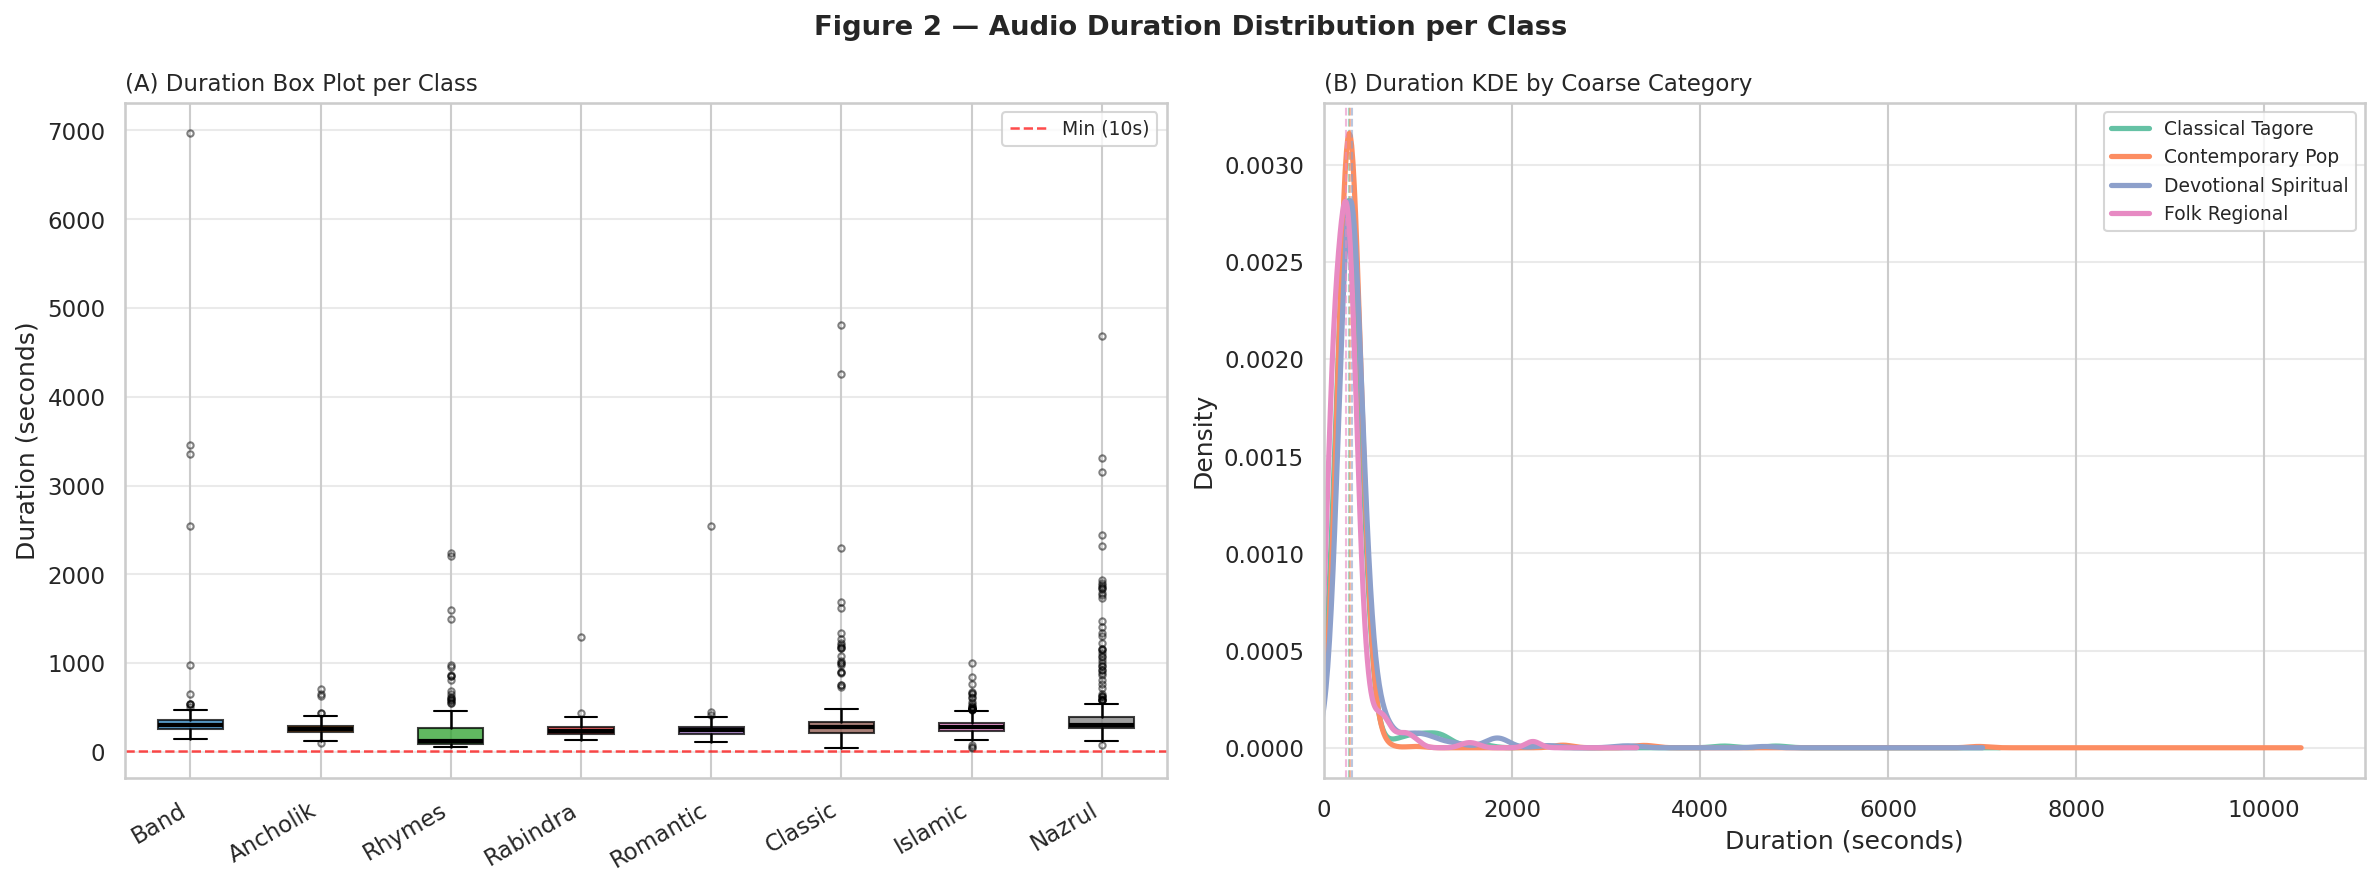

Saved: /kaggle/working/part1_outputs/figures/fig02_duration_distribution.png


In [6]:
# ============================================================
# CELL 6 ▸ Figure 2 — Audio Duration Distribution
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Figure 2 — Audio Duration Distribution per Class', fontweight='bold')

clrs = [CLASS_PAL[c] for c in CLASS_NAMES]

# Panel A: box plot
ax = axes[0]
data = [file_df[file_df['label']==c]['duration_s'].values for c in CLASS_NAMES]
bp   = ax.boxplot(data, patch_artist=True, notch=False,
                  medianprops=dict(color='black', linewidth=2),
                  whiskerprops=dict(linewidth=1.2),
                  flierprops=dict(marker='o', markersize=3, alpha=0.5))
for patch, c in zip(bp['boxes'], clrs):
    patch.set_facecolor(c); patch.set_alpha(0.75)
ax.set_xticklabels(SHORT_NAMES, rotation=30, ha='right')
ax.set_ylabel('Duration (seconds)')
ax.set_title('(A) Duration Box Plot per Class', loc='left', fontsize=11)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)
ax.axhline(SEG_DUR, color='red', ls='--', lw=1.2, alpha=0.7,
           label=f'Min ({SEG_DUR}s)')
ax.legend(fontsize=9)

# Panel B: KDE by coarse class
ax = axes[1]
for coarse in COARSE_NAMES:
    cls_in = [k for k,v in COARSE_MAP.items() if v==coarse]
    vals   = file_df[file_df['label'].isin(cls_in)]['duration_s']
    vals.plot.kde(ax=ax, label=coarse.replace('_',' '),
                  color=COARSE_PAL[coarse], linewidth=2.5)
    ax.axvline(vals.median(), color=COARSE_PAL[coarse],
               ls='--', lw=1, alpha=0.6)
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Density')
ax.set_xlim(left=0)
ax.set_title('(B) Duration KDE by Coarse Category', loc='left', fontsize=11)
ax.legend(fontsize=9); ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)

plt.tight_layout()
path = os.path.join(FIG_DIR, 'fig02_duration_distribution.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

Loading one sample per class for waveform visualisation...


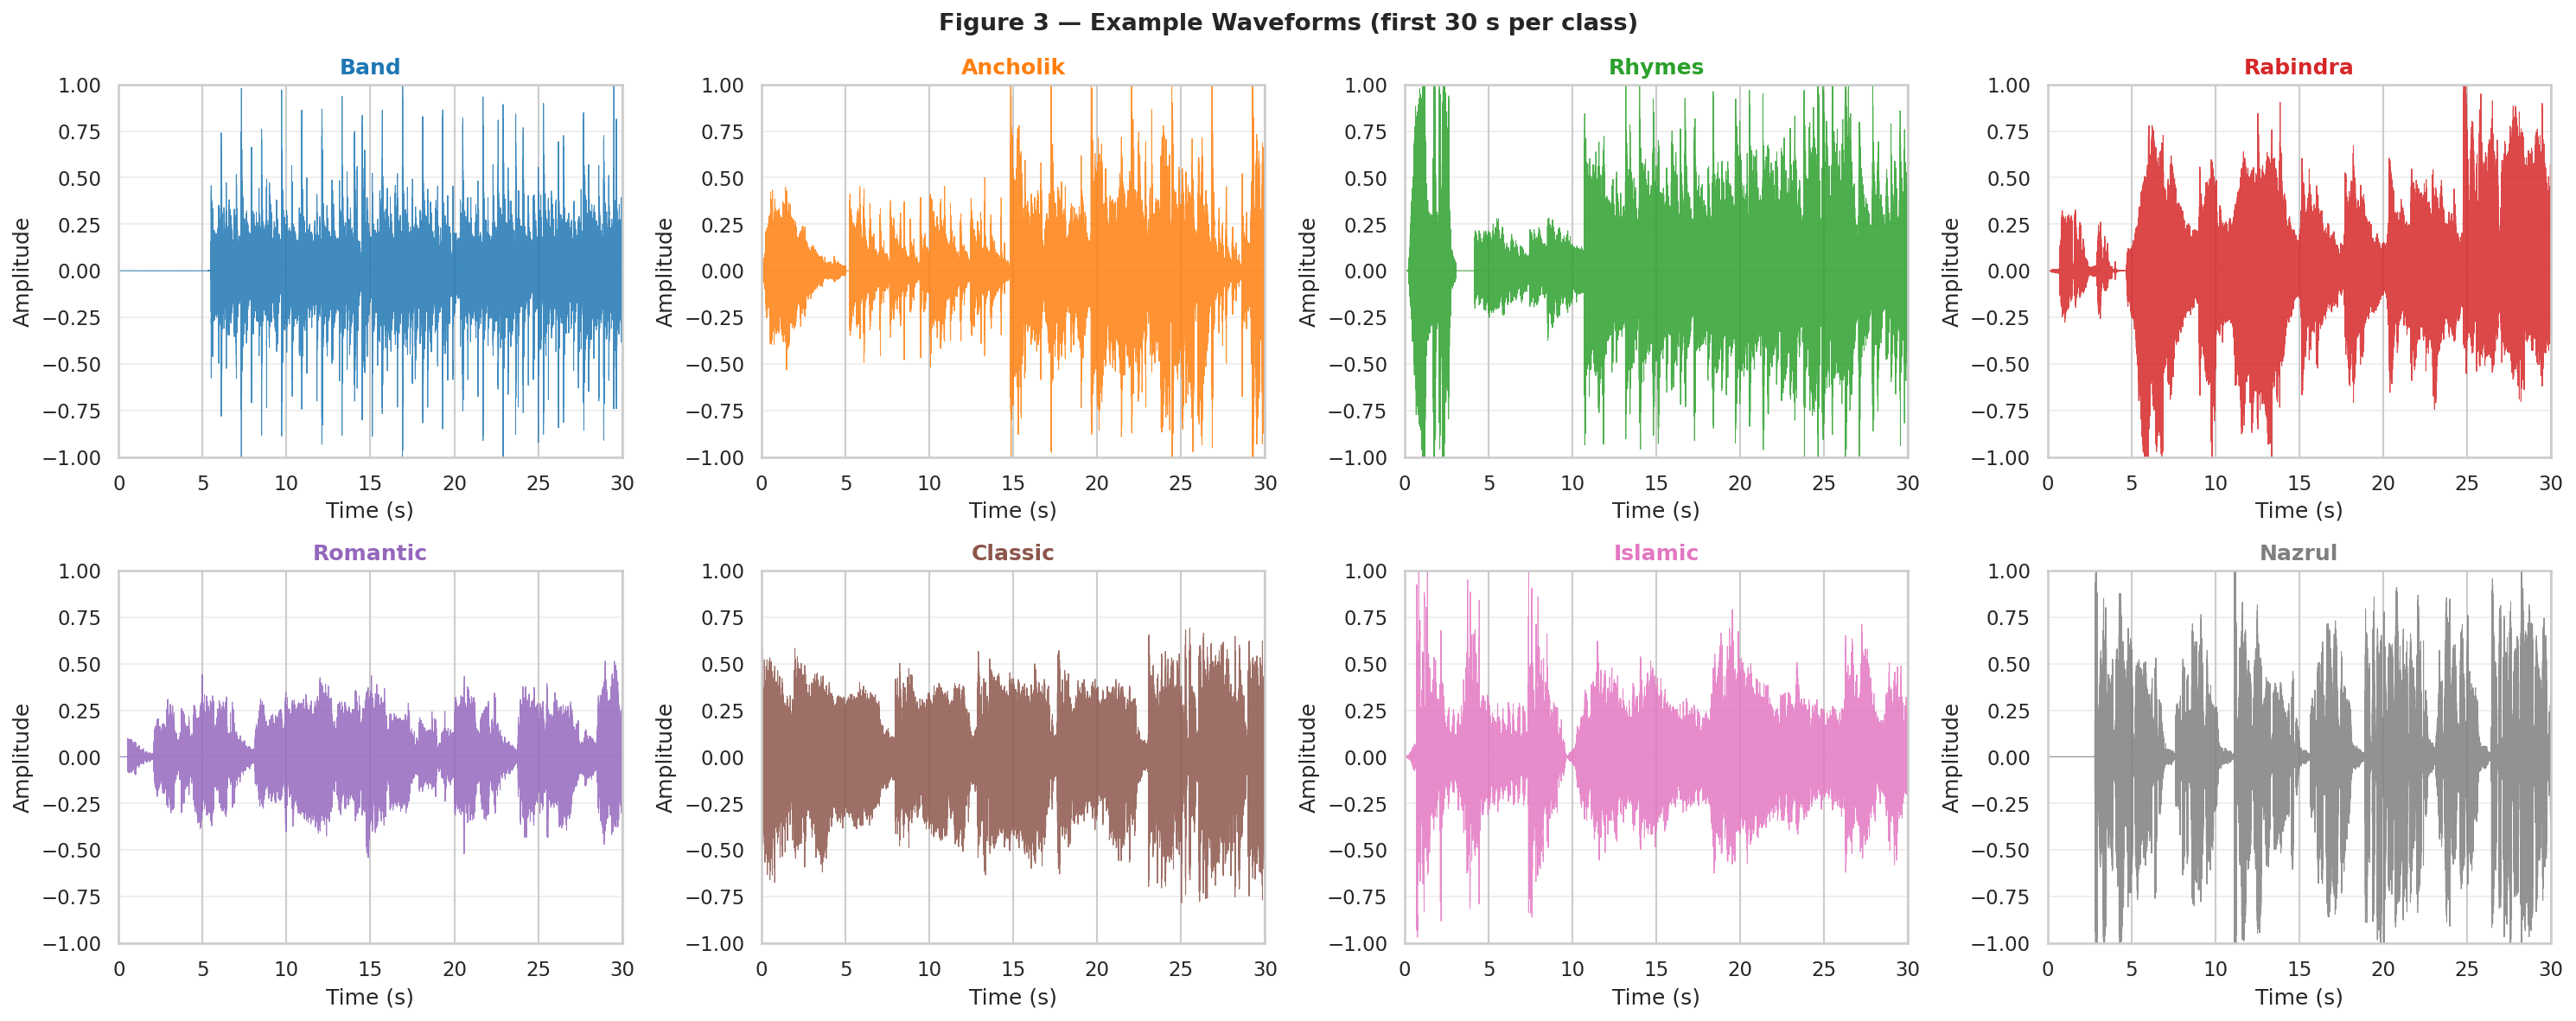

Saved: /kaggle/working/part1_outputs/figures/fig03_waveforms.png


In [7]:
# ============================================================
# CELL 7 ▸ Figure 3 — Waveform Examples (8-panel)
# ============================================================
print('Loading one sample per class for waveform visualisation...')

SHOW_DUR = 30          # seconds to display

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
fig.suptitle('Figure 3 — Example Waveforms (first 30 s per class)',
             fontweight='bold')
axes = axes.flatten()

for ax, cls in zip(axes, CLASS_NAMES):
    fpath = file_df[file_df['label']==cls]['filepath'].iloc[0]
    try:
        y, sr = librosa.load(fpath, sr=SR, duration=float(SHOW_DUR), mono=True)
        t = np.linspace(0, len(y)/SR, len(y))
        ax.plot(t, y, color=CLASS_PAL[cls], lw=0.5, alpha=0.85)
        ax.set_xlim(0, SHOW_DUR)
        ax.set_ylim(-1, 1)
    except Exception as e:
        ax.text(0.5, 0.5, f'Load error\n{e}', ha='center',
                transform=ax.transAxes, fontsize=8)
    ax.set_title(CLASS_SHORT[cls], fontsize=12, fontweight='bold',
                 color=CLASS_PAL[cls])
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude')
    ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)

plt.tight_layout()
path = os.path.join(FIG_DIR, 'fig03_waveforms.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

In [8]:
# ============================================================
# CELL 9 ▸ 5-Fold Song-Disjoint Stratified CV Assignment
# ============================================================
# Each audio FILE is assigned to exactly one fold (0-4).
# All segments from that file inherit the same fold.
# StratifiedKFold ensures all 8 classes appear in every fold.
# fold_assignments.csv is the single source of truth for all
# downstream parts (3, 4, 5).

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(CLASS_NAMES)
file_df = file_df.copy()
file_df['label_id'] = le.transform(file_df['label'])

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
file_df['fold'] = -1

for k, (_, test_idx) in enumerate(
        skf.split(file_df['filepath'], file_df['label_id'])):
    file_df.loc[test_idx, 'fold'] = k

assert (file_df['fold'] == -1).sum() == 0, 'Some files have no fold!'

print('5-fold stratified song-disjoint assignment complete.')
print()
print(f'  {"Fold":<6} {"Files":>7}  {"Est. segs":>10}  Classes present')
print(f'  {"-"*6} {"-"*7}  {"-"*10}  {"-"*20}')
for k in range(N_FOLDS):
    sub = file_df[file_df['fold'] == k]
    cls_present = sub['label'].unique()
    print(f'  {k:<6} {len(sub):>7,}  '
          f'{sub["n_segs_est"].sum():>10,}  '
          f'{len(cls_present)}/8 classes')

5-fold stratified song-disjoint assignment complete.

  Fold     Files   Est. segs  Classes present
  ------ -------  ----------  --------------------
  0          374      11,609  8/8 classes
  1          374      12,922  8/8 classes
  2          374      11,769  8/8 classes
  3          374      13,630  8/8 classes
  4          374      10,649  8/8 classes


In [9]:
# ============================================================
# CELL 10 ▸ Fold Verification (4 checks)
# ============================================================
print('Running fold verification checks...\n')
all_pass = True

# Check 1: zero file leakage across folds
print('CHECK 1 — Zero file leakage between folds:')
for k in range(N_FOLDS):
    fold_fps   = set(file_df[file_df['fold'] == k]['filepath'])
    other_fps  = set(file_df[file_df['fold'] != k]['filepath'])
    overlap    = fold_fps & other_fps
    icon = 'PASS' if not overlap else f'FAIL ({len(overlap)} leaked)'
    print(f'  [{icon}]  Fold {k}')
    if overlap: all_pass = False

# Check 2: all 8 classes in every fold
print('\nCHECK 2 — All 8 classes in every fold:')
for k in range(N_FOLDS):
    present = set(file_df[file_df['fold'] == k]['label'])
    missing = set(CLASS_NAMES) - present
    icon = 'PASS' if not missing else f'FAIL missing {missing}'
    print(f'  [{icon}]  Fold {k}: {len(present)}/8 classes')
    if missing: all_pass = False

# Check 3: no unassigned files
print('\nCHECK 3 — No unassigned files:')
n_bad = (file_df['fold'] == -1).sum()
print(f'  [{"PASS" if n_bad==0 else f"FAIL {n_bad}"}]  '
      f'Unassigned = {n_bad}')
if n_bad: all_pass = False

# Check 4: imbalance ratio across folds
print('\nCHECK 4 — File imbalance ratio per fold (lower = more balanced):')
for k in range(N_FOLDS):
    sub    = file_df[file_df['fold'] == k]
    counts = sub.groupby('label').size()
    ratio  = counts.max() / counts.min()
    icon = 'PASS' if ratio < 4 else 'WARN'
    print(f'  [{icon}]  Fold {k}: max/min = {ratio:.2f}x')

print()
if all_pass:
    print('ALL CHECKS PASSED — fold assignment is valid.')
else:
    print('SOME CHECKS FAILED — review above.')

Running fold verification checks...

CHECK 1 — Zero file leakage between folds:
  [PASS]  Fold 0
  [PASS]  Fold 1
  [PASS]  Fold 2
  [PASS]  Fold 3
  [PASS]  Fold 4

CHECK 2 — All 8 classes in every fold:
  [PASS]  Fold 0: 8/8 classes
  [PASS]  Fold 1: 8/8 classes
  [PASS]  Fold 2: 8/8 classes
  [PASS]  Fold 3: 8/8 classes
  [PASS]  Fold 4: 8/8 classes

CHECK 3 — No unassigned files:
  [PASS]  Unassigned = 0

CHECK 4 — File imbalance ratio per fold (lower = more balanced):
  [PASS]  Fold 0: max/min = 2.13x
  [PASS]  Fold 1: max/min = 2.10x
  [PASS]  Fold 2: max/min = 2.13x
  [PASS]  Fold 3: max/min = 2.13x
  [PASS]  Fold 4: max/min = 2.13x

ALL CHECKS PASSED — fold assignment is valid.


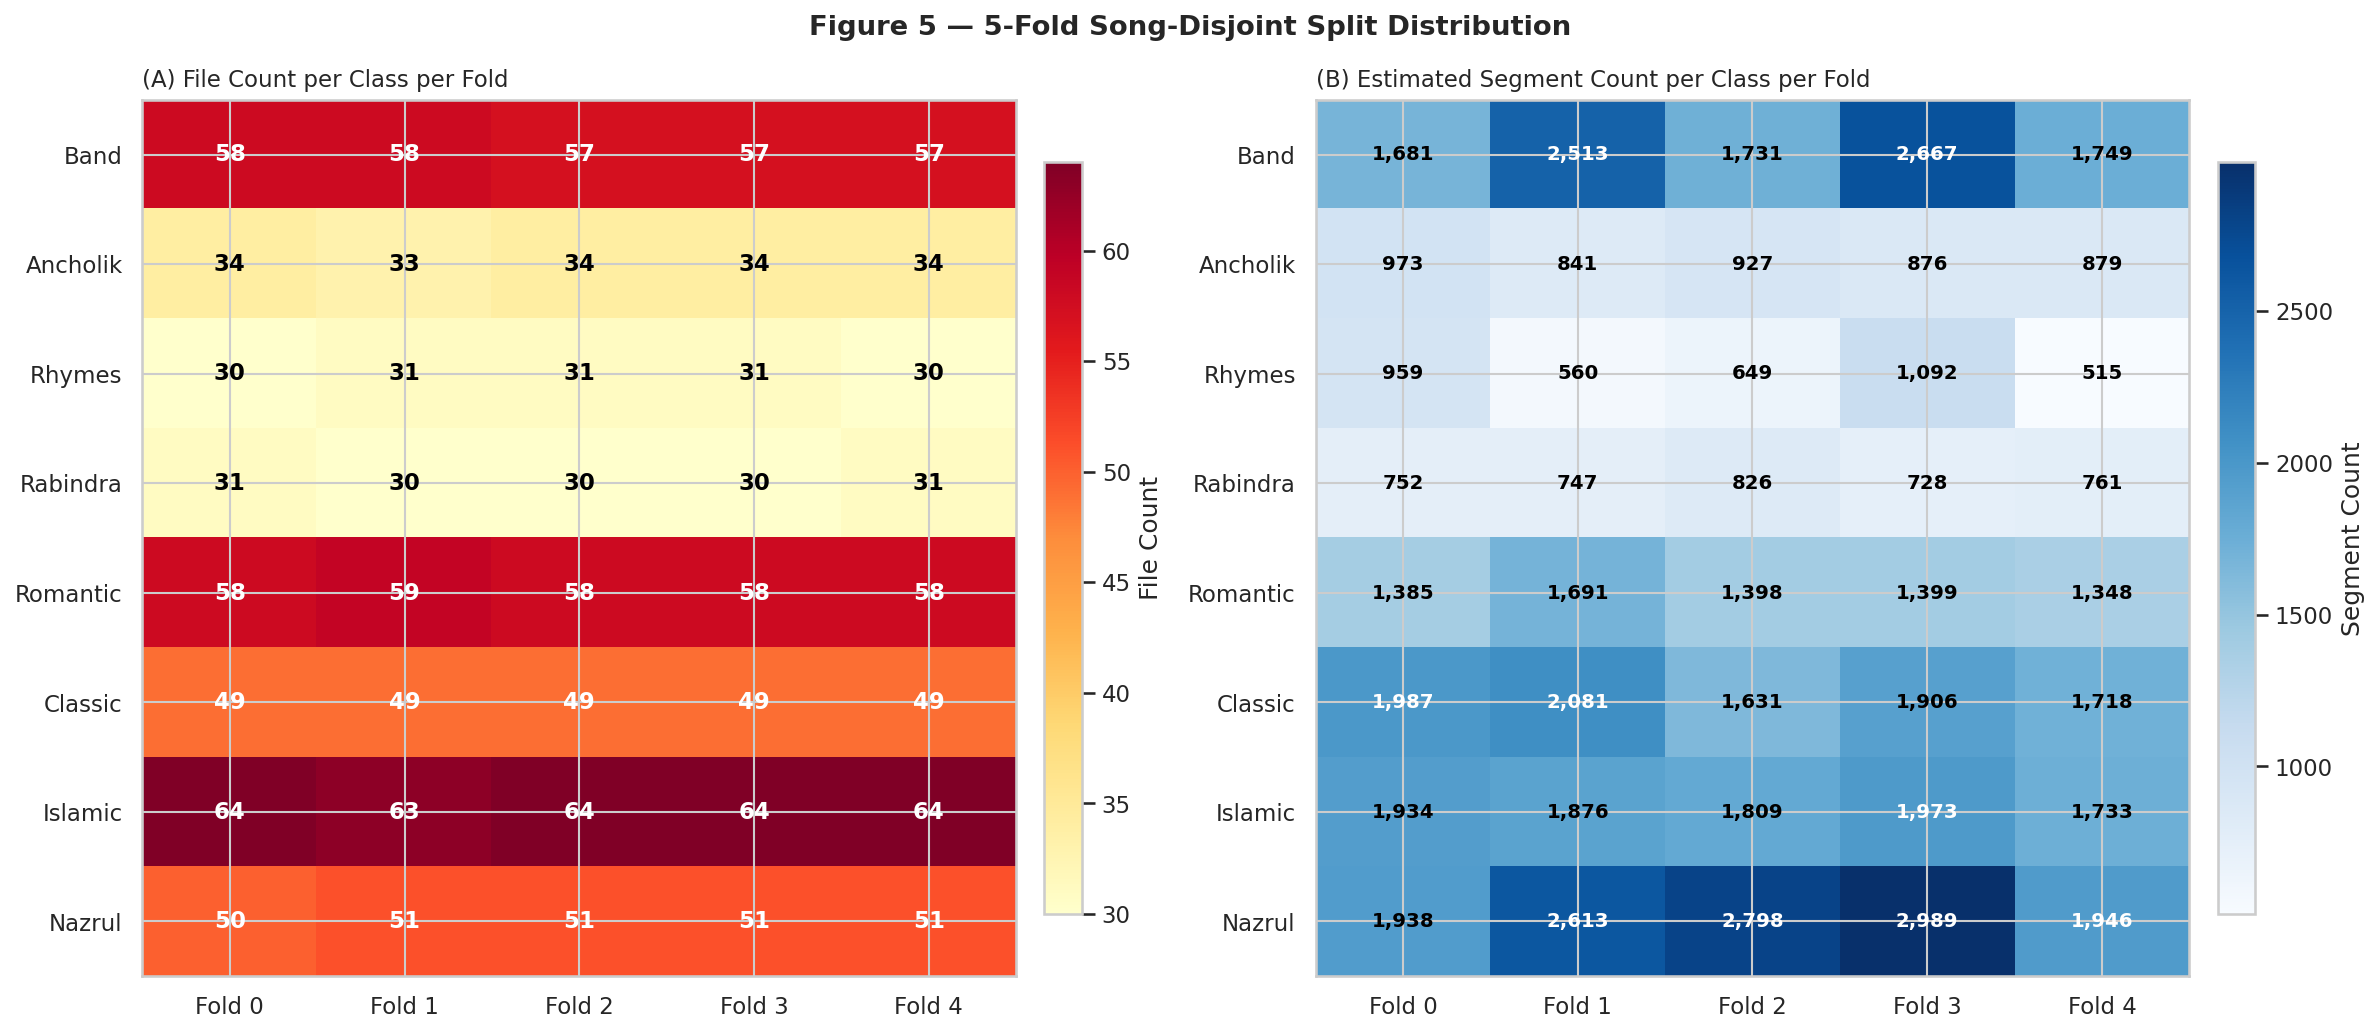

Saved: /kaggle/working/part1_outputs/figures/fig05_fold_distribution.png


In [10]:
# ============================================================
# CELL 11 ▸ Figure 5 — Fold Distribution Heatmap
# ============================================================
# Shows segment counts per class per fold.
# A well-stratified assignment looks uniform across rows.

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Figure 5 — 5-Fold Song-Disjoint Split Distribution',
             fontweight='bold')

# Panel A: file count heatmap
ax = axes[0]
heat_files = np.zeros((N_CLASSES, N_FOLDS), dtype=int)
for i, cls in enumerate(CLASS_NAMES):
    for k in range(N_FOLDS):
        heat_files[i, k] = ((file_df['label'] == cls) &
                             (file_df['fold']  == k)).sum()

im = ax.imshow(heat_files, cmap='YlOrRd', aspect='auto')
for i in range(N_CLASSES):
    for k in range(N_FOLDS):
        v = heat_files[i, k]
        clr = 'white' if v > heat_files.max()*0.65 else 'black'
        ax.text(k, i, str(v), ha='center', va='center',
                fontsize=11, fontweight='bold', color=clr)
ax.set_xticks(range(N_FOLDS))
ax.set_xticklabels([f'Fold {k}' for k in range(N_FOLDS)], fontsize=11)
ax.set_yticks(range(N_CLASSES))
ax.set_yticklabels(SHORT_NAMES, fontsize=11)
ax.set_title('(A) File Count per Class per Fold', loc='left', fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.03, label='File Count')

# Panel B: estimated segment count heatmap
ax = axes[1]
heat_segs = np.zeros((N_CLASSES, N_FOLDS), dtype=int)
for i, cls in enumerate(CLASS_NAMES):
    for k in range(N_FOLDS):
        mask = (file_df['label']==cls) & (file_df['fold']==k)
        heat_segs[i, k] = file_df.loc[mask, 'n_segs_est'].sum()

im2 = ax.imshow(heat_segs, cmap='Blues', aspect='auto')
for i in range(N_CLASSES):
    for k in range(N_FOLDS):
        v = heat_segs[i, k]
        clr = 'white' if v > heat_segs.max()*0.65 else 'black'
        ax.text(k, i, f'{v:,}', ha='center', va='center',
                fontsize=9.5, fontweight='bold', color=clr)
ax.set_xticks(range(N_FOLDS))
ax.set_xticklabels([f'Fold {k}' for k in range(N_FOLDS)], fontsize=11)
ax.set_yticks(range(N_CLASSES))
ax.set_yticklabels(SHORT_NAMES, fontsize=11)
ax.set_title('(B) Estimated Segment Count per Class per Fold',
             loc='left', fontsize=11)
plt.colorbar(im2, ax=ax, fraction=0.04, pad=0.03, label='Segment Count')

plt.tight_layout()
path = os.path.join(FIG_DIR, 'fig05_fold_distribution.png')
plt.savefig(path); plt.show()
print(f'Saved: {path}')

In [13]:
# ============================================================
# CELL 12 ▸ Save fold_assignments.csv + ZIP
# ============================================================
import os
import pandas as pd
import zipfile

# Save fold assignments (one row per audio file)
fold_csv = os.path.join(OUT_DIR, 'fold_assignments.csv')
save_cols = ['filepath','label','coarse','song_id','fold','duration_s','n_segs_est']
file_df[save_cols].to_csv(fold_csv, index=False)
print(f'fold_assignments.csv saved  →  {len(file_df):,} rows')

# Save dataset statistics (Table 1 for the paper)
stats_rows = []
for cls in CLASS_NAMES:
    sub = file_df[file_df['label'] == cls]
    stats_rows.append({
        'Class'       : cls,
        'Coarse'      : COARSE_MAP[cls],
        'Files'       : len(sub),
        'Est_Segments': int(sub['n_segs_est'].sum()),
        'Dur_mean_s'  : round(sub['duration_s'].mean(), 1),
        'Dur_total_min': round(sub['duration_s'].sum()/60, 1),
    })
stats_df = pd.DataFrame(stats_rows)
totals = {'Class':'TOTAL','Coarse':'—',
          'Files'        : stats_df['Files'].sum(),
          'Est_Segments' : int(stats_df['Est_Segments'].sum()),
          'Dur_mean_s'   : round(file_df['duration_s'].mean(),1),
          'Dur_total_min': round(file_df['duration_s'].sum()/60,1)}
stats_df = pd.concat([stats_df, pd.DataFrame([totals])], ignore_index=True)
stats_df.to_csv(os.path.join(OUT_DIR,'dataset_statistics.csv'), index=False)

print()
print('Paper Table 1 — Dataset Statistics:')
print(stats_df.to_string(index=False))

# ZIP
zip_path = os.path.join(WORK_DIR, 'part1_outputs.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(fold_csv, 'fold_assignments.csv')
    zf.write(os.path.join(OUT_DIR,'dataset_statistics.csv'),
             'dataset_statistics.csv')
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp = os.path.join(FIG_DIR, fname)
            zf.write(fp, f'figures/{fname}')
            sz = os.path.getsize(fp)/1024
            print(f'  + figures/{fname:<40} {sz:.0f} KB')

zip_size = os.path.getsize(zip_path)/1e6

# FIX: Compute the imbalance ratio outside the f-string first
class_counts = file_df.groupby("label").size()
imbalance_ratio = class_counts.max() / class_counts.min()

print()
print('='*55)
print(f'  PART 1 COMPLETE')
print('='*55)
print(f'  ZIP: {zip_path}  ({zip_size:.1f} MB)')
print()
print('  Contents:')
print('  ├── fold_assignments.csv      <- needed by Parts 3, 4, 5')
print('  ├── dataset_statistics.csv   <- Table 1 for the paper')
print('  └── figures/ (5 PNG, 300 DPI)')
print()
print(f'  Total clean files : {len(file_df):,}')
print(f'  Imbalance ratio   : {imbalance_ratio:.2f}x')

fold_assignments.csv saved  →  1,870 rows

Paper Table 1 — Dataset Statistics:
                  Class               Coarse  Files  Est_Segments  Dur_mean_s  Dur_total_min
 Bangla_Band_Collection     Contemporary_Pop    287         10341       365.2         1746.7
        Bangla_ancholik        Folk_Regional    169          4496       271.1          763.6
     Bangla_baby_rhymes        Folk_Regional    153          3775       251.9          642.4
Bangla_rabindra_sangeet     Classical_Tagore    152          3814       256.0          648.5
        Bangla_romantic     Contemporary_Pop    291          7221       253.2         1228.0
         Classic_Songs_     Classical_Tagore    245          9323       385.8         1575.4
         Islamic_Melody Devotional_Spiritual    319          9325       297.1         1579.4
          Nazrul_Geeti_ Devotional_Spiritual    254         12284       488.2         2066.5
                  TOTAL                    —   1870         60579       328.9       